# Datos del equipo (COMPLETAR)

Identificador de grupo: Grupo G2.

| Nombre y apellido | % de contribución |
|-------------------|-------------------|
|Arantzazu Otal Alberro|     20%        |
|Juan José García García|    20%        |
|Gonzalo Torres Aparicio|    20%        |
|Rodrigo Collado Díaz|       20%        |
|Ángel García Consuegra Trujillo| 20%   |


In [ ]:
!pip install pandas numpy matplotlib seaborn aif360[inFairness] fairlearn

## 1. CONFIGURACIÓN INICIAL Y CARGA DE LIBRERÍAS

In [ ]:
# Imports necesarios
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Visualización alternativa
from IPython.display import display, HTML

# Scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    confusion_matrix, roc_auc_score, classification_report,
    ConfusionMatrixDisplay
)

# AIF360
import aif360
from aif360.datasets import CompasDataset
from aif360.metrics import BinaryLabelDatasetMetric, ClassificationMetric
from aif360.algorithms.preprocessing import Reweighing
from aif360.algorithms.preprocessing import DisparateImpactRemover
from aif360.algorithms.inprocessing import AdversarialDebiasing
from aif360.algorithms.postprocessing import EqOddsPostprocessing

# Fairlearn
import fairlearn
from fairlearn.metrics import (
    MetricFrame, selection_rate, demographic_parity_difference,
    equalized_odds_difference
)
from fairlearn.reductions import ExponentiatedGradient, DemographicParity, EqualizedOdds
from fairlearn.postprocessing import ThresholdOptimizer

# Configuración de visualización
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
np.random.seed(42)

print("✓ Librerías cargadas correctamente")
print(f"AIF360 version: {aif360.__version__}")
print(f"Fairlearn version: {fairlearn.__version__}")


✓ Librerías cargadas correctamente
AIF360 version: 0.6.1
Fairlearn version: 0.15.0


## 2. CARGA Y EXPLORACIÓN DEL DATASET COMPAS

El dataset COMPAS contiene información sobre acusados en el condado de Broward, Florida, entre 2013-2014, incluyendo su puntuación de riesgo de reincidencia y si reincidieron dentro de 2 años.

In [ ]:
# NO EJECUTAR, MEJOR USAR LA FORMA DE PYTHON DE LA SIGUIENTE CELDA

# Descargar el dataset COMPAS si no está ya descargado
# !wget -nv -O ~/miniconda3/envs/ia_confiable/lib/python3.10/site-packages/aif360/data/raw/compas/compas-scores-two-years.csv https://raw.githubusercontent.com/propublica/compas-analysis/master/compas-scores-two-years.csv

In [ ]:
# Descargar el dataset COMPAS si no está ya descargado usando Python

from pathlib import Path
from urllib.request import urlretrieve

import aif360.datasets.compas_dataset as compas_module

# Obtener la ruta del paquete AIF360 instalado en tu entorno virtual
aif360_dir = Path(compas_module.__file__).resolve().parent.parent

# Crear la carpeta donde CompasDataset espera encontrar el CSV
data_dir = aif360_dir / "data" / "raw" / "compas"
data_dir.mkdir(parents=True, exist_ok=True)

# Descargar el dataset original de ProPublica
url = (
    "https://raw.githubusercontent.com/"
    "propublica/compas-analysis/master/"
    "compas-scores-two-years.csv"
)

csv_path = data_dir / "compas-scores-two-years.csv"

if not csv_path.exists():
    urlretrieve(url, csv_path)
    print(f"Dataset descargado en: {csv_path}")
else:
    print(f"El dataset ya existe en: {csv_path}")

El dataset ya existe en: /usr/local/lib/python3.13/dist-packages/aif360/data/raw/compas/compas-scores-two-years.csv


In [ ]:


# Cargar dataset COMPAS usando AIF360
dataset_orig = CompasDataset(
    protected_attribute_names=['race'],
    privileged_classes=[['Caucasian']],
    categorical_features=['sex', 'age_cat', 'c_charge_degree', 'c_charge_desc'],
    features_to_keep=[
        'sex', 'age', 'age_cat', 'race',
        'juv_fel_count', 'juv_misd_count', 'juv_other_count',
        'priors_count', 'c_charge_degree', 'c_charge_desc',
        'two_year_recid'
    ]
)

# Información básica del dataset
display(HTML(f"""
<h1>Información básica del dataset 'CompasDataset'</h1>

<ul>
    <li><b>Número total de instancias:</b> {dataset_orig.features.shape[0]}</li>
    <li><b>Número de features:</b> {dataset_orig.features.shape[1]}</li>
    <li><b>Nombres de features (solo las 5 primeras):</b> {dataset_orig.feature_names[:5]} ...</li>
    <li><b>Atributo protegido:</b> {dataset_orig.protected_attribute_names}</li>
    <li><b>Grupo privilegiado:</b> Caucasian (Etiqueta 1)</li>
    <li><b>Grupo no privilegiado:</b> African-American (Etiqueta 0)</li>
</ul>
"""))


In [ ]:
# Convertir a DataFrame para análisis exploratorio
df = pd.DataFrame(
    data=dataset_orig.features,
    columns=dataset_orig.feature_names
)
df['recidivism'] = dataset_orig.labels.ravel()
df['race_binary'] = dataset_orig.protected_attributes.ravel()

# Mapear valores para mejor interpretación
df['race_label'] = df['race_binary'].map({1: 'Caucasian', 0: 'African-American'})

print("Primeras filas del dataset:")
df.head(10)


Primeras filas del dataset:


,age,race,juv_fel_count,juv_misd_count,juv_other_count,priors_count,sex=Female,sex=Male,age_cat=25 - 45,age_cat=Greater than 45,...,c_charge_desc=Viol Pretrial Release Dom Viol,c_charge_desc=Viol Prot Injunc Repeat Viol,c_charge_desc=Violation License Restrictions,c_charge_desc=Violation Of Boater Safety Id,c_charge_desc=Violation of Injunction Order/Stalking/Cyberstalking,c_charge_desc=Voyeurism,c_charge_desc=arrest case no charge,recidivism,race_binary,race_label
0,69.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,African-American
1,34.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,African-American
2,24.0,0.0,0.0,0.0,1.0,4.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,African-American
3,44.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,African-American
4,41.0,1.0,0.0,0.0,0.0,14.0,0.0,1.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,Caucasian
5,43.0,0.0,0.0,0.0,0.0,3.0,0.0,1.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,African-American
6,39.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,Caucasian
7,27.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,Caucasian
8,23.0,0.0,0.0,0.0,0.0,3.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,African-American
9,37.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,Caucasian


### 2.1 Análisis de Distribución Demográfica

In [ ]:
# Distribución por raza
race_distribution = df['race_label'].value_counts()

# EJERCICIO 1: Completa el código para imprimir la distribución racial del dataset y los porcentajes.
# === INICIO SOLUCIÓN ===

# Calcular el porcentaje de cada grupo racial
race_percentages = df['race_label'].value_counts(normalize=True) * 100


display(HTML(f"""<h1>Distribución por raza</h1>

<h3>Número de personas por grupo racial</h3>
{race_distribution.round(2)
    .rename_axis(race_distribution.index.name or "race")
    .reset_index(name="count")
    .to_html(index=False)}

<h3>Porcentaje de personas por grupo racial</h3>
{race_percentages.round(2)
    .rename_axis(race_percentages.index.name or "race")
    .reset_index(name="percent")
    .to_html(index=False)}

"""
))
# === FIN SOLUCIÓN ===

race_label,count
African-American,4067
Caucasian,2100
race_label,percent
African-American,65.95
Caucasian,34.05


In [ ]:
# Tasa de reincidencia por raza
# print("=== TASA DE REINCIDENCIA POR RAZA ===")

# EJERCICIO 2: Calcula la tasa de reincidencia para cada grupo racial e imprime la diferencia absoluta.
# === INICIO SOLUCIÓN ===

# Calculamos la tasa media de reincidencia para cada grupo racial
recidivism_by_race = df.groupby('race_label')['recidivism'].mean() * 100

# Calculamos la diferencia absoluta entre los grupos
absolute_difference = abs(
    recidivism_by_race['African-American'] -
    recidivism_by_race['Caucasian']
)


display(HTML(f"""
<h2>Tasa de reincidencia por grupo racial (%)</h2>
{recidivism_by_race.round(2)
    .rename_axis(recidivism_by_race.index.name or "race")
    .reset_index(name="percent")
    .to_html(index=False)}
<p><b> Diferencia absoluta entre los grupos:</b> {absolute_difference:.2f} % </p>
"""
))

# === FIN SOLUCIÓN ===

race_label,percent
African-American,48.86
Caucasian,39.14


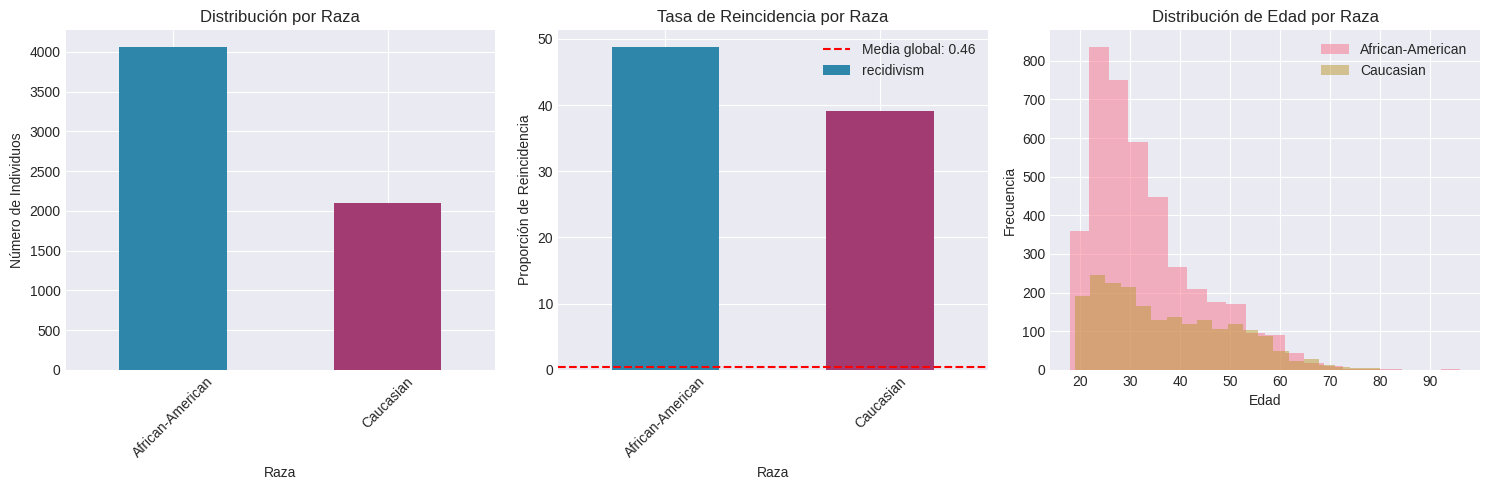

In [ ]:
# Visualización de distribuciones
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Distribución racial
race_distribution.plot(kind='bar', ax=axes[0], color=['#2E86AB', '#A23B72'])
axes[0].set_title('Distribución por Raza')
axes[0].set_xlabel('Raza')
axes[0].set_ylabel('Número de Individuos')
axes[0].tick_params(axis='x', rotation=45)

# Tasa de reincidencia por raza
recidivism_by_race.plot(kind='bar', ax=axes[1], color=['#2E86AB', '#A23B72'])
axes[1].set_title('Tasa de Reincidencia por Raza')
axes[1].set_xlabel('Raza')
axes[1].set_ylabel('Proporción de Reincidencia')
axes[1].axhline(y=df['recidivism'].mean(), color='red', linestyle='--',
               label=f'Media global: {df["recidivism"].mean():.2f}')
axes[1].legend()
axes[1].tick_params(axis='x', rotation=45)

# Distribución de edad por raza
for race in df['race_label'].unique():
    subset = df[df['race_label'] == race]
    axes[2].hist(subset['age'], alpha=0.5, label=race, bins=20)
axes[2].set_title('Distribución de Edad por Raza')
axes[2].set_xlabel('Edad')
axes[2].set_ylabel('Frecuencia')
axes[2].legend()

plt.tight_layout()
plt.show()


 ### 2.2 Análisis de Correlaciones y Features

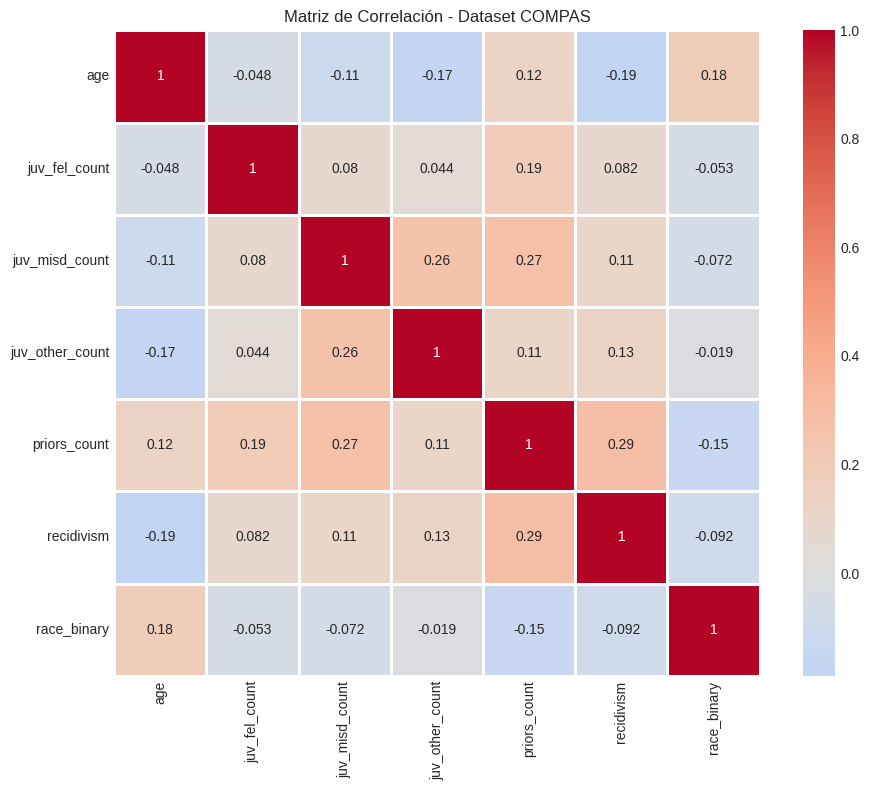

Feature,Correlation
recidivism,1.000000
priors_count,0.290534
juv_other_count,0.125781
juv_misd_count,0.110201
juv_fel_count,0.081996
race_binary,-0.092431
age,-0.189191
Feature,Correlation
race_binary,1.000000
age,0.180676


In [ ]:
# Análisis de correlaciones con el outcome y el atributo protegido
numeric_cols = ['age', 'juv_fel_count', 'juv_misd_count',
                'juv_other_count', 'priors_count']

correlation_data = df[numeric_cols + ['recidivism', 'race_binary']].copy()

# Matriz de correlación
plt.figure(figsize=(10, 8))
correlation_matrix = correlation_data.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0,
            square=True, linewidths=1)
plt.title('Matriz de Correlación - Dataset COMPAS')
plt.tight_layout()
plt.show()


display(HTML(f"""
<h2>Correlaciones con reincidencia</h2>

{correlation_matrix['recidivism'].sort_values(ascending=False)
    .rename_axis("Feature")
    .reset_index(name="Correlation")
    .to_html(index=False)}

<h2>Correlaciones con raza</h2>

{correlation_matrix['race_binary'].sort_values(ascending=False)
    .rename_axis("Feature")
    .reset_index(name="Correlation")
    .to_html(index=False)}
"""))


## 3. PREPARACIÓN DE DATOS Y MODELO BASE

In [ ]:
# División train/test manteniendo proporciones
dataset_train, dataset_test = dataset_orig.split([0.7], shuffle=True, seed=42)

# Extraer features y labels
X_train = dataset_train.features
y_train = dataset_train.labels.ravel()
sensitive_train = dataset_train.protected_attributes.ravel()

X_test = dataset_test.features
y_test = dataset_test.labels.ravel()
sensitive_test = dataset_test.protected_attributes.ravel()

# Normalización de features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


display(HTML(f"""
<h2>Preparación de datos del modelo base</h2>

<ul>
    <li><b>Tamaño del conjunto de entrenamiento:</b> {X_train.shape}</li>
    <li><b>Tamaño del conjunto de prueba:</b> {X_test.shape}</li>
</ul>
"""))

### 3.1 Entrenamiento del Modelo Base (Sin Mitigación)

In [ ]:
# EJERCICIO 3: Entrena un modelo de regresión logística base.
# Completa el código para entrenar el modelo y obtener predicciones.

# === INICIO SOLUCIÓN ===
# Entrenar modelo base
baseline_model = LogisticRegression(max_iter=1000, random_state=42)
baseline_model.fit(X_train_scaled, y_train)

# Predicciones

# Predicciones de clase
y_pred_baseline = baseline_model.predict(X_test_scaled)

# Probabilidad estimada de la clase positiva (reincidencia)
y_pred_proba_baseline = baseline_model.predict_proba(X_test_scaled)[:, 1]

# === FIN SOLUCIÓN ===


display(HTML(f"""<h2>Métricas del Modelo Base (Sin Mitigación)</h2>

<ul>
    <li><b>Accuracy:</b> {accuracy_score(y_test, y_pred_baseline):.3f}</li>
    <li><b>Precision:</b> {precision_score(y_test, y_pred_baseline):.3f}</li>
    <li><b>Recall:</b> {recall_score(y_test, y_pred_baseline):.3f}</li>
    <li><b>ROC-AUC:</b> {roc_auc_score(y_test, y_pred_proba_baseline):.3f}</li>
</ul>
"""))

### 3.2 Evaluación de Sesgo en el Modelo Base

In [ ]:
# Crear dataset con predicciones para métricas AIF360
dataset_pred_baseline = dataset_test.copy()
dataset_pred_baseline.labels = y_pred_baseline.reshape(-1, 1)

# Calcular métricas de equidad con AIF360
privileged_groups = [{'race': 1}]  # Caucasian
unprivileged_groups = [{'race': 0}]  # African-American

metric_baseline = ClassificationMetric(
    dataset_test,
    dataset_pred_baseline,
    unprivileged_groups=unprivileged_groups,
    privileged_groups=privileged_groups
)


display(HTML(f"""<h2>Métricas de Equidad del Modelo Base (AIF360)</h2>

<ul>
    <li><b>Disparate Impact:</b> {metric_baseline.disparate_impact():.3f}</li>
    <li><b>Statistical Parity Difference:</b> {metric_baseline.statistical_parity_difference():.3f}</li>
    <li><b>Equal Opportunity Difference:</b> {metric_baseline.equal_opportunity_difference():.3f}</li>
    <li><b>Average Odds Difference:</b> {metric_baseline.average_abs_odds_difference():.3f}</li>
    <li><b>Theil Index:</b> {metric_baseline.theil_index():.3f}</li>
</ul>
"""))

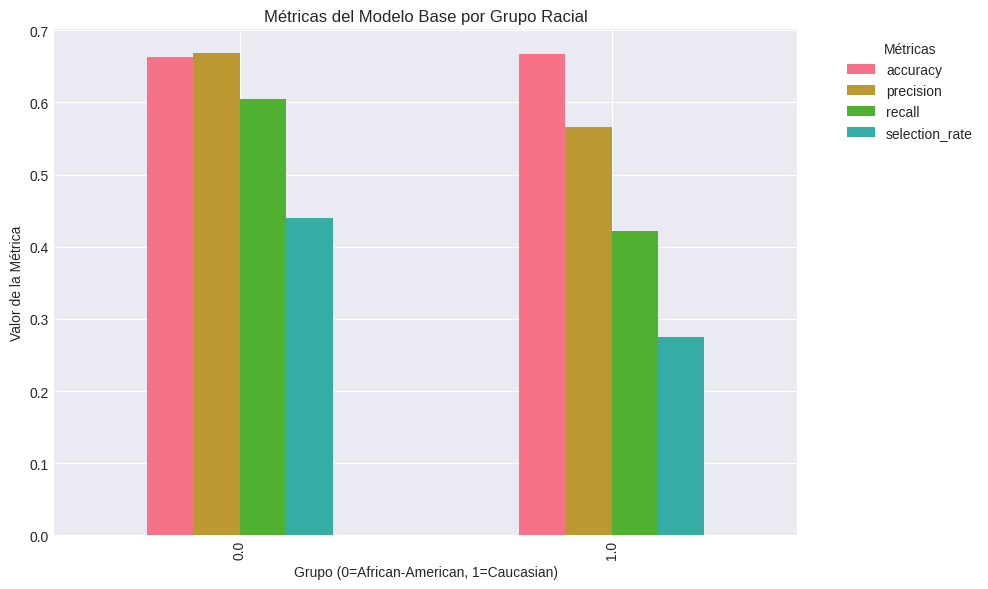

In [ ]:
# Análisis detallado por grupo usando Fairlearn
from sklearn.metrics import confusion_matrix

# Crear DataFrame con predicciones y grupos
results_df = pd.DataFrame({
    'y_true': y_test,
    'y_pred': y_pred_baseline,
    'race': sensitive_test
})

# MetricFrame para análisis estructurado
metrics = {
    'accuracy': accuracy_score,
    'precision': precision_score,
    'recall': recall_score,
    'selection_rate': selection_rate
}

mf_baseline = MetricFrame(
    metrics=metrics,
    y_true=y_test,
    y_pred=y_pred_baseline,
    sensitive_features=sensitive_test
)


display(HTML(f"""<h2>Métricas por grupo del Modelo Base (Fairlearn)</h2>

{mf_baseline.by_group
    .reset_index()
    .to_html(index=False)}

<h2>Diferencias entre grupos</h2>

{mf_baseline.difference()
    .rename_axis("Metrics")
    .reset_index(name="Difference")
    .to_html(index=False)}
"""))

# Visualización de métricas por grupo
mf_baseline.by_group.plot(kind='bar', figsize=(10, 6))
plt.title('Métricas del Modelo Base por Grupo Racial')
plt.xlabel('Grupo (0=African-American, 1=Caucasian)')
plt.ylabel('Valor de la Métrica')
plt.legend(title='Métricas', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


 ### 3.3 Análisis de Matrices de Confusión por Grupo

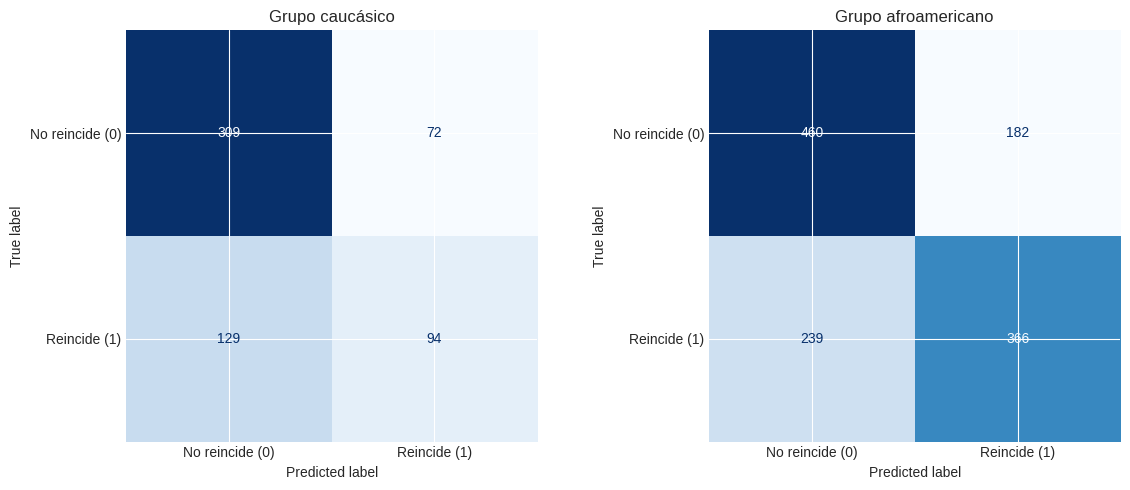

In [ ]:
# EJERCICIO 4: Analiza las matrices de confusión para cada grupo racial.
# Completa el código para calcular y visualizar las matrices de confusión.
# === INICIO SOLUCIÓN ===
# Matrices de confusión por grupo
mask_caucasian = (sensitive_test == 1)
mask_african_american = (sensitive_test == 0)

cm_caucasian = confusion_matrix(
    y_test[mask_caucasian],
    y_pred_baseline[mask_caucasian],
    labels=[0, 1]
)

cm_african_american = confusion_matrix(
    y_test[mask_african_american],
    y_pred_baseline[mask_african_american],
    labels=[0, 1]
)

# Visualización
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

disp_caucasian = ConfusionMatrixDisplay(
    confusion_matrix=cm_caucasian,
    display_labels=["No reincide (0)", "Reincide (1)"]
)
disp_caucasian.plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Grupo caucásico")

disp_african_american = ConfusionMatrixDisplay(
    confusion_matrix=cm_african_american,
    display_labels=["No reincide (0)", "Reincide (1)"]
)
disp_african_american.plot(ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set_title("Grupo afroamericano")

plt.tight_layout()
plt.show()

# === FIN SOLUCIÓN ===

# EJERCICIO 5: Calcula e imprime la False Positive Rate (FPR) entre los grupos raciales.
# === INICIO SOLUCIÓN ===

# Calcular False Positive Rate para cada grupo

# Descomponer las matrices de confusión
tn_caucasian, fp_caucasian, fn_caucasian, tp_caucasian = (
    cm_caucasian.ravel()
)

tn_african_american, fp_african_american, fn_african_american, tp_african_american = (
    cm_african_american.ravel()
)

# Calcular la FPR para cada grupo
fpr_caucasian = (
    fp_caucasian / (fp_caucasian + tn_caucasian)
    if (fp_caucasian + tn_caucasian) > 0
    else np.nan
)

fpr_african_american = (
    fp_african_american / (fp_african_american + tn_african_american)
    if (fp_african_american + tn_african_american) > 0
    else np.nan
)

# Calcular la diferencia absoluta entre las tasas
if not np.isnan(fpr_caucasian) and not np.isnan(fpr_african_american):
    fpr_difference = abs(fpr_caucasian - fpr_african_american)
    difference_html = f"<p><b>Diferencia absoluta:</b> {fpr_difference:.3%}</p>"
else:
    difference_html = """
    <p><b>Diferencia absoluta:</b> No disponible.
    Al menos un grupo no tiene observaciones con resultado real negativo.</p>
    """

display(HTML(f"""
<h2>False Positive Rate por grupo racial</h2>
<ul>
    <li><b>Grupo caucásico:</b> {fpr_caucasian:.3%}</li>
    <li><b>Grupo afroamericano:</b> {fpr_african_american:.3%}</li>
</ul>
{difference_html}
"""))

# === FIN SOLUCIÓN ===

## 4. TÉCNICAS DE MITIGACIÓN DE SESGO

Ahora aplicaremos diferentes técnicas de mitigación y compararemos sus resultados.

### 4.1 Pre-processing: Reweighing

In [ ]:
# Aplicar Reweighing
RW = Reweighing(
    unprivileged_groups=unprivileged_groups,
    privileged_groups=privileged_groups
)

# Transformar dataset de entrenamiento
dataset_train_rw = RW.fit_transform(dataset_train)

# Entrenar modelo con datos reponderados
X_train_rw = dataset_train_rw.features
y_train_rw = dataset_train_rw.labels.ravel()
weights_rw = dataset_train_rw.instance_weights.ravel()

# Normalizar features
X_train_rw_scaled = scaler.fit_transform(X_train_rw)

# Entrenar modelo
model_rw = LogisticRegression(max_iter=1000, random_state=42)
model_rw.fit(X_train_rw_scaled, y_train_rw, sample_weight=weights_rw)

# Predicciones
y_pred_rw = model_rw.predict(X_test_scaled)

# Evaluación
accuracy_rw = accuracy_score(y_test, y_pred_rw)

# Métricas de equidad
dataset_pred_rw = dataset_test.copy()
dataset_pred_rw.labels = y_pred_rw.reshape(-1, 1)

metric_rw = ClassificationMetric(
    dataset_test,
    dataset_pred_rw,
    unprivileged_groups=unprivileged_groups,
    privileged_groups=privileged_groups
)


display(HTML(f"""<h2>Métricas de Reweighing</h2>

<ul>
    <li><b>Accuracy:</b> {accuracy_rw:.3f}</li>
    <li><b>Disparate Impact:</b> {metric_rw.disparate_impact():.3f}</li>
    <li><b>Statistical Parity Difference:</b> {metric_rw.statistical_parity_difference():.3f}</li>
    <li><b>Equal Opportunity Difference:</b> {metric_rw.equal_opportunity_difference():.3f}</li>
</ul>
"""))


### 4.2 In-processing: Exponentiated Gradient con Demographic Parity

In [ ]:
from fairlearn.reductions import ExponentiatedGradient, DemographicParity

# EJERCICIO 6: Implementa mitigación usando ExponentiatedGradient con DemographicParity.
# Completa el código para entrenar el modelo con restricciones de equidad.

# === INICIO SOLUCIÓN ===
# Configurar el mitigador con DemographicParity

# Configurar el estimador base
estimator = LogisticRegression(max_iter=1000, random_state=42)

# Configurar el mitigador con la restricción de paridad demográfica
mitigator = ExponentiatedGradient(
    estimator=estimator,
    constraints=DemographicParity()
)

# Entrenar con restricciones de equidad
mitigator.fit(
    X_train_scaled,
    y_train,
    sensitive_features=sensitive_train
)

# Predicciones
y_pred_expgrad = mitigator.predict(X_test_scaled)

# === FIN SOLUCIÓN ===

# Evaluación
accuracy_expgrad = accuracy_score(y_test, y_pred_expgrad)

# Métricas con Fairlearn
mf_expgrad = MetricFrame(
    metrics={'accuracy': accuracy_score, 'selection_rate': selection_rate},
    y_true=y_test,
    y_pred=y_pred_expgrad,
    sensitive_features=sensitive_test
)

# Calcular Disparate Impact
sr_african = mf_expgrad.by_group.loc[0, 'selection_rate']
sr_caucasian = mf_expgrad.by_group.loc[1, 'selection_rate']
di_expgrad = sr_african / sr_caucasian if sr_caucasian > 0 else 0


display(HTML(f"""<h2>Métricas de Exponentiated Gradient con Demographic Parity</h2>

<ul>
    <li><b>Accuracy:</b> {accuracy_expgrad:.3f}</li>
    <li><b>Disparate Impact:</b> {di_expgrad:.3f}</li>
    <li><b>Selection Rate Difference:</b> {mf_expgrad.difference()['selection_rate']:.3f}</li>
</ul>

<h2>Métricas por grupo</h2>

{mf_expgrad.by_group.reset_index().to_html(index=False)}
"""))


sensitive_feature_0,accuracy,selection_rate
0.0,0.655974,0.392943
1.0,0.655629,0.379139


### 4.3 In-processing: Exponentiated Gradient con Equalized Odds

In [ ]:
from fairlearn.reductions import EqualizedOdds

# EJERCICIO 7: Implementa ExponentiatedGradient con EqualizedOdds.
# Completa el código para aplicar la restricción de Equalized Odds.

# === INICIO SOLUCIÓN ===
# Configurar mitigador con Equalized Odds

# Configurar el estimador base
estimator_eo = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Configurar el mitigador con Equalized Odds
mitigator_eo = ExponentiatedGradient(
    estimator=estimator_eo,
    constraints=EqualizedOdds()
)

# Entrenar
mitigator_eo.fit(
    X_train_scaled,
    y_train,
    sensitive_features=sensitive_train
)

# Predicciones
y_pred_eo = mitigator_eo.predict(X_test_scaled)

# === FIN SOLUCIÓN ===

# Evaluación
accuracy_eo = accuracy_score(y_test, y_pred_eo)

# Métricas de equidad con AIF360
dataset_pred_eo = dataset_test.copy()
dataset_pred_eo.labels = y_pred_eo.reshape(-1, 1)

metric_eo = ClassificationMetric(
    dataset_test,
    dataset_pred_eo,
    unprivileged_groups=unprivileged_groups,
    privileged_groups=privileged_groups
)

display(HTML(f"""<h2>Métricas de Exponentiated Gradient con Equalized Odds</h2>

<ul>
    <li><b>Accuracy:</b> {accuracy_eo:.3f}</li>
    <li><b>Disparate Impact:</b> {metric_eo.disparate_impact():.3f}</li>
    <li><b>Statistical Parity Difference:</b> {metric_eo.statistical_parity_difference():.3f}</li>
    <li><b>Equal Opportunity Difference:</b> {metric_eo.equal_opportunity_difference():.3f}</li>
    <li><b>Average Odds Difference:</b> {metric_eo.average_abs_odds_difference():.3f}</li>
</ul>
"""))


### 4.4 Post-processing: Threshold Optimizer

In [ ]:
# Crear conjunto de validación para ajustar umbrales
X_train_sub, X_val, y_train_sub, y_val, sens_train_sub, sens_val = train_test_split(
    X_train_scaled, y_train, sensitive_train,
    test_size=0.3, random_state=42, stratify=y_train
)

# Entrenar modelo en subconjunto
model_for_threshold = LogisticRegression(max_iter=1000, random_state=42)
model_for_threshold.fit(X_train_sub, y_train_sub)

# Configurar ThresholdOptimizer
postprocessor = ThresholdOptimizer(
    estimator=model_for_threshold,
    constraints='demographic_parity',
    objective='accuracy_score',
    prefit=True
)

# Ajustar umbrales
postprocessor.fit(X_val, y_val, sensitive_features=sens_val)

# Predicciones con umbrales optimizados
y_pred_threshold = postprocessor.predict(X_test_scaled, sensitive_features=sensitive_test)

# Evaluación
accuracy_threshold = accuracy_score(y_test, y_pred_threshold)

# Métricas con Fairlearn
mf_threshold = MetricFrame(
    metrics={'accuracy': accuracy_score, 'selection_rate': selection_rate},
    y_true=y_test,
    y_pred=y_pred_threshold,
    sensitive_features=sensitive_test
)

# Calcular Disparate Impact (*** AÑADIDO ADICIONAL *** esta parte se usa para calcular el disparate impact de la tecnica Threshold, no el de ExpGrad-DP que es el que se usaba en la tabla resumen)
sr_african_threshold = mf_threshold.by_group.loc[0, 'selection_rate']
sr_caucasian_threshold = mf_threshold.by_group.loc[1, 'selection_rate']
di_threshold = sr_african_threshold / sr_caucasian_threshold if sr_caucasian_threshold > 0 else 0


display(HTML(f"""<h2>Métricas de Threshold Optimizer</h2>

<ul>
    <li><b>Accuracy:</b> {accuracy_threshold:.3f}</li>
    <li><b>Disparate Impact:</b> {di_threshold:.3f}</li>
    <li><b>Selection Rate Difference:</b> {mf_threshold.difference()['selection_rate']:.3f}</li>
</ul>

<h3>Métricas por grupo</h3>

{mf_threshold.by_group.reset_index().to_html(index=False)}
"""))


sensitive_feature_0,accuracy,selection_rate
0.0,0.631115,0.353649
1.0,0.658940,0.346026


## 5. COMPARACIÓN DE TÉCNICAS

| Modelo o técnica                              | Biblioteca utilizada para mitigar sesgos | Biblioteca utilizada para evaluar la equidad |
| --------------------------------------------- | ---------------------------------------- | -------------------------------------------- |
| **Baseline**                                  | Ninguna técnica específica de mitigación | AIF360                                       |
| **Reweighing**                                | AIF360                                   | AIF360                                       |
| **ExponentiatedGradient + DemographicParity** | Fairlearn                                | Fairlearn                                    |
| **ExponentiatedGradient + EqualizedOdds**     | Fairlearn                                | AIF360                                       |
| **ThresholdOptimizer**                        | Fairlearn                                | Fairlearn                                    |

>Nota metodológica: En este experimento se utilizan AIF360 y Fairlearn tanto para aplicar técnicas de mitigación como para evaluar sus resultados. Aunque ambas bibliotecas proporcionan métricas de equidad con objetivos similares, sus convenciones de cálculo y presentación pueden diferir. Por ejemplo, AIF360 calcula el *Statistical Parity Difference* como una diferencia con signo entre los grupos privilegiado y no privilegiado, siendo negativo para indicar tasa menor de prediciones favorables para el grupo no privilegiado y positivo justo lo contrario. Por otro lado, Fairlearn lo hace mediante *MetricFrame.difference()*, que calcula por defecto la diferencia entre el valor máximo y el mínimo de las tasas de selección, sin conservar el signo y sin permitir distinguir a que grupo se pertenece.

>Por este motivo, los resultados de las distintas técnicas son útiles para estudiar las tendencias generales y comparar el compromiso entre rendimiento predictivo y equidad, pero no son estrictamente comparables en todos sus aspectos cuando se han calculado con convenciones diferentes. Esta consideración debe tenerse en cuenta al interpretar la tabla siguiente, especialmente en las métricas Disparate Impact y Statistical Parity Difference.

In [ ]:
# Compilar todos los resultados
results_summary = {
    'Baseline': {
        'accuracy': accuracy_score(y_test, y_pred_baseline),
        'disparate_impact': metric_baseline.disparate_impact(),
        'stat_parity_diff': metric_baseline.statistical_parity_difference(),
        'equal_opp_diff': metric_baseline.equal_opportunity_difference()
    },
    'Reweighing': {
        'accuracy': accuracy_score(y_test, y_pred_rw),
        'disparate_impact': metric_rw.disparate_impact(),
        'stat_parity_diff': metric_rw.statistical_parity_difference(),
        'equal_opp_diff': metric_rw.equal_opportunity_difference()
    },
    'ExpGrad-DP': {
        'accuracy': accuracy_score(y_test, y_pred_expgrad),
        'disparate_impact': di_expgrad,
        'stat_parity_diff': mf_expgrad.difference()['selection_rate'],
        'equal_opp_diff': None  # No optimizado para esto
    },
    'ExpGrad-EO': {
        'accuracy': accuracy_score(y_test, y_pred_eo),
        'disparate_impact': metric_eo.disparate_impact(),
        'stat_parity_diff': metric_eo.statistical_parity_difference(),
        'equal_opp_diff': metric_eo.equal_opportunity_difference()
    },
    'ThresholdOpt': {
        'accuracy': accuracy_score(y_test, y_pred_threshold),
        # 'disparate_impact': sr_african / sr_caucasian if sr_caucasian > 0 else 0, # ESTOS DATOS PROVIENEN DE LA TECNICA ExpGrad NO DE LA DE ThresholdOpt
        'disparate_impact': di_threshold,
        'stat_parity_diff': mf_threshold.difference()['selection_rate'],
        'equal_opp_diff': None
    }
}

# Crear DataFrame con resultados
results_df = pd.DataFrame(results_summary).T
results_df = results_df.round(3)

# print("=== COMPARACIÓN DE TODAS LAS TÉCNICAS ===")
# print(results_df)



display(HTML(f"""
<h2>Comparación de todas las técnicas</h2>

{results_df.rename_axis("Técnica").reset_index().to_html(index=False)}
"""))


Técnica,accuracy,disparate_impact,stat_parity_diff,equal_opp_diff
Baseline,0.664,0.773,-0.165,-0.095
Reweighing,0.653,0.975,-0.016,0.031
ExpGrad-DP,0.656,1.036,0.014,NaN
ExpGrad-EO,0.661,0.947,-0.033,0.010
ThresholdOpt,0.640,1.022,0.008,NaN


### 5.1 Visualización del compromiso Accuracy vs Equidad

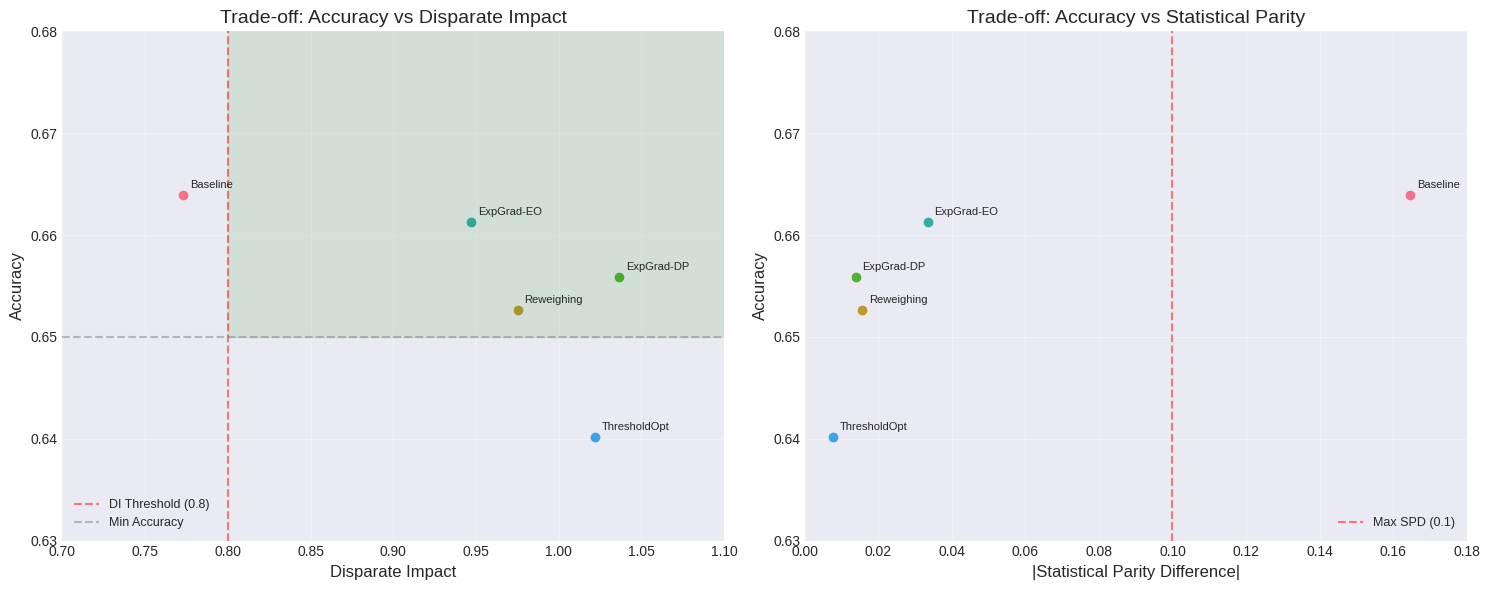

In [ ]:
# EJERCICIO 8: Crea una visualización del compromiso entre accuracy y equidad.
# Completa los fragmentos de código para crear un gráfico de dispersión.
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Gráfico 1: Accuracy vs Disparate Impact
for method, metrics in results_summary.items():
    if metrics['disparate_impact'] is not None:
        # === INICIO SOLUCIÓN ===

        # print(method, metrics['disparate_impact'], metrics['accuracy'])

        axes[0].scatter(
            metrics['disparate_impact'],
            metrics['accuracy']
        )
        axes[0].annotate(
            method,
            (metrics['disparate_impact'], metrics['accuracy']),
            xytext=(5, 5),
            textcoords='offset points',
            fontsize=8
        )

axes[0].set_xlim(0.7, 1.1)
axes[0].set_ylim(0.63, 0.68)

        # === FIN SOLUCIÓN ===

axes[0].axvline(x=0.8, color='red', linestyle='--', alpha=0.5,
                label='DI Threshold (0.8)')
axes[0].axhline(y=0.65, color='gray', linestyle='--', alpha=0.5,
                label='Min Accuracy')
axes[0].fill_between([0.8, 1.2], 0.65, 1.0, alpha=0.1, color='green')
axes[0].set_xlabel('Disparate Impact', fontsize=12)
axes[0].set_ylabel('Accuracy', fontsize=12)
axes[0].set_title('Trade-off: Accuracy vs Disparate Impact', fontsize=14)
axes[0].legend(loc='lower left', fontsize=9)
axes[0].grid(True, alpha=0.3)

# Gráfico 2: Statistical Parity Difference
for method, metrics in results_summary.items():
    if metrics['stat_parity_diff'] is not None:
        # === INICIO SOLUCIÓN ===

        # print(method, abs(metrics['stat_parity_diff']), metrics['accuracy'])

        axes[1].scatter(
            abs(metrics['stat_parity_diff']),
            metrics['accuracy']
        )
        axes[1].annotate(
            method,
            (abs(metrics['stat_parity_diff']), metrics['accuracy']),
            xytext=(5, 5),
            textcoords='offset points',
            fontsize=8
        )

axes[1].set_xlim(0, 0.18)
axes[1].set_ylim(0.63, 0.68)

        # === FIN SOLUCIÓN ===

axes[1].axvline(x=0.1, color='red', linestyle='--', alpha=0.5,
                label='Max SPD (0.1)')
axes[1].set_xlabel('|Statistical Parity Difference|', fontsize=12)
axes[1].set_ylabel('Accuracy', fontsize=12)
axes[1].set_title('Trade-off: Accuracy vs Statistical Parity', fontsize=14)
axes[1].legend(loc='lower right', fontsize=9)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


### 5.2 Análisis de Métricas por Grupo

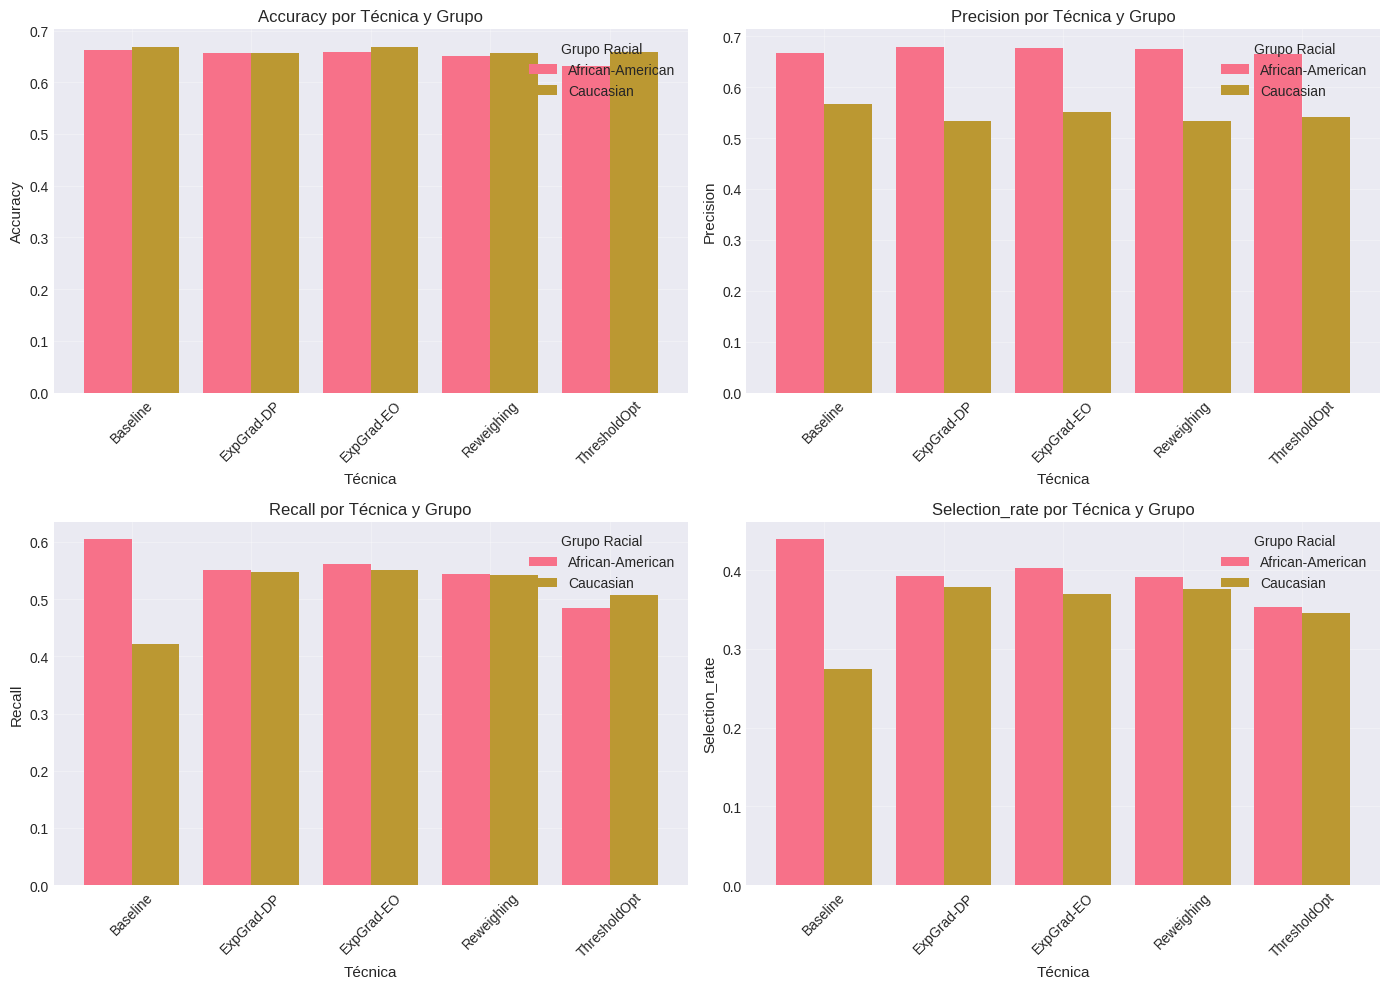

In [ ]:
# Comparación detallada de métricas por grupo racial
techniques = ['Baseline', 'Reweighing', 'ExpGrad-DP', 'ExpGrad-EO', 'ThresholdOpt']
predictions = [y_pred_baseline, y_pred_rw, y_pred_expgrad, y_pred_eo, y_pred_threshold]

# Calcular métricas por técnica y grupo
group_metrics = []

for tech, preds in zip(techniques, predictions):
    # African-American
    aa_mask = sensitive_test == 0
    aa_metrics = {
        'technique': tech,
        'group': 'African-American',
        'accuracy': accuracy_score(y_test[aa_mask], preds[aa_mask]),
        'precision': precision_score(y_test[aa_mask], preds[aa_mask], zero_division=0),
        'recall': recall_score(y_test[aa_mask], preds[aa_mask]),
        'selection_rate': preds[aa_mask].mean()
    }
    group_metrics.append(aa_metrics)

    # Caucasian
    c_mask = sensitive_test == 1
    c_metrics = {
        'technique': tech,
        'group': 'Caucasian',
        'accuracy': accuracy_score(y_test[c_mask], preds[c_mask]),
        'precision': precision_score(y_test[c_mask], preds[c_mask], zero_division=0),
        'recall': recall_score(y_test[c_mask], preds[c_mask]),
        'selection_rate': preds[c_mask].mean()
    }
    group_metrics.append(c_metrics)

group_metrics_df = pd.DataFrame(group_metrics)

# Visualización
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

metrics_to_plot = ['accuracy', 'precision', 'recall', 'selection_rate']

for idx, metric in enumerate(metrics_to_plot):
    ax = axes[idx // 2, idx % 2]

    pivot_data = group_metrics_df.pivot(index='technique',
                                        columns='group',
                                        values=metric)
    pivot_data.plot(kind='bar', ax=ax, width=0.8)
    ax.set_title(f'{metric.capitalize()} por Técnica y Grupo', fontsize=12)
    ax.set_xlabel('Técnica', fontsize=11)
    ax.set_ylabel(metric.capitalize(), fontsize=11)
    ax.legend(title='Grupo Racial')
    ax.grid(True, alpha=0.3)
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


## 6. EJERCICIO 9

Basándote en todos los análisis, escribe tu recomendación. Completa este apartado con tu análisis y recomendación final.

#### 1. Property-Based Testing

- Técnica recomendada:
    > Si observamos en el apartado 5 la tabla de comparación de todas las técnica vemos que la que tiene mejor grado de exactitud es Baseline con un 0.664, sin embargo, en el impacto dispar es 0.773 esto puede significar presencia de sesgo, Reweighing es quien tiene mejor impacto dispar al tener 0.975. En la diferencia de paridad estadística quien tiene mejor valor es el que se acerca mas a 0 por lo tanto el mejor es ThresholdOpt con 0.008 y en la diferencia de igualdad de oportunidades el mejor valor mas cercano a 0 es el de 0.010 correspondiente a ExpGrad-EO.
    
    > Por todo esto se recomienda, **la técnica de Reweighing**, ya que ofrece un equilibrio más robusto, completo y consistente entre precisión y equidad.



#### 2. Justificación

- ¿Por qué eligió esta técnica?
    > Es la más completa, logra corregir todas las métricas de equidad a la vez con un rendimiento excelente, no deja métricas vacías y protege todos los flancos del modelo manteniendo una alta precisión.

- ¿Qué compromisos acepta?
    > El de rendimiento y equidad mutua. Aceptamos una perdida de precisión de 0.664 (Baseline) a 0.653. Lo bueno es que se gana un Impacto Dispar casi perfecto del 0.975. Se acepta la pequeña desviación en Diferencia de Igualdad de Oportunidades que queda a 0.031 y la Paridad Estadística a -0.016 a cambio de tener un modelo blindado en todas las métricas simultáneamente.


- ¿Qué métricas de equidad prioriza y por qué?
    > Se prioriza el impacto dispar y la paridad estadística. Se consigue una métrica de impacto dispar casi perfecta del 0.975 con esto se busca conseguir que el porcentaje de personas seleccionadas en grupo protegido sea prácticamente igual al del grupo no protegido. Con una paridad estadística del -0.016 logramos que la diferencia de asignación de resultados positivos entre grupos se acerque bastante a 0. Al balancear los datos de entrada para que ambos grupos tengan las mismas proporciones de éxito en la fase de entrenamiento, el modelo resultante aprende de forma natural a no discriminar en las tasas de selección general. Por eso, estas métricas mejoran de forma tan drástica y simultánea.

#### 3. Métricas clave de la solución recomendada

- Accuracy:
    > 0.653

- Disparate Impact:
    > 0.975
    
- Equal Opportunity Difference:
    > 0.031


#### 4. Consideraciones éticas

- ¿Qué implicaciones tiene para los individuos afectados?
    > Lo más grave que creemos que implica, es que in falso positivo que no va a reincidir sea clasificado como de alto riesgo, lo que para esa persona tiene consecuencias graves como que se le deniega la libertad bajo fianza, tenga una sentencia más prolongada o la libertad condicional tenga ccondiciones más estrictas.  Por otro laado, si se diera el caso contrario, un falso negativo clasifica a un reincidente como de bajo riesgo, lo que afectaría a la seguridad pública.

- ¿Cómo afecta a los diferentes grupos raciales?
    > El modelo penaliza desproporcionadamente al grupo afroamericano, presentándolos de forma equivocada como guturos reincidentes con mucha más frecuencia que el grupo caucásico, 28.349% contra 18.898% como veiamos en el punto 3.3. Las técnicas de mitigfación de sesgos aplicadas reducen la disparidad, igualando las tasas de selección o equilibrando los tipos de error, asi conseguimos que el impacto del modelo sea más justo entre ambos grupos.

- ¿Es aceptable el nivel de sesgo restante?
    > Aunque las técnicas de mitigación logran métricas de equidad altasm,como el disparate impact muy cercano a 1, el nivel de error no consideramos que es aceptable para su uso real ya que la precisión del modelo es del 65%~. Creemos que este tipo de decisiones tan importantes automatizadas que privan a las personas de su libertad con una tasa de error de más de 30% plantea problemas éticos, incluso si esos errores se distribuyen equitativamente entre grupos raciales.


#### 5. Limitaciones y trabajo futuro
- ¿Qué limitaciones tiene su solución?
    > Lo principal es el trade-off entre precisión y equidad, cuando hicimos que el modelo sea más justo con los grupos, la capacidad predictiva bajó. Taambién las técnicas que usamos se aplican sobre los sesgos en los datos de entrada o en la salida del modelo, pero los datos históricos de arrestos contienen sesgos que ya vienen del sietema de la justicia penal y casos de discriminación de la policía que no pueden corregirse completamente solo con ajustes algorítmicos.
- ¿Qué análisis adicionales recomendaría?
    > Recomendaríamos que se hiciera un análisis donde se observe cómo el sesgo afecta a subgrupos específicos, por ejemplo aalgo tipo mujeres afroamericanas frente a hombres caucásicos, evaluando los atributos raza y sexo combinados. Quizás también se podría probar evaluar modelos de clasificación más complejos, como random forest, a ver si se consigue una precisión mayor, revisando que atributos están actuando como variables sustitutas de la raza.

## CONCLUSIONES

En esta práctica hemos:
1. Identificado sesgos significativos en el sistema COMPAS original
2. Aplicado múltiples técnicas de mitigación (pre, in, y post-processing)
3. Evaluado el compromiso entre accuracy y equidad
4. Seleccionado una solución que balancea rendimiento y justicia algorítmica

**Reflexión final**: El caso COMPAS ilustra la importancia crítica de auditar y mitigar sesgos en sistemas de IA que afectan la libertad y vida de las personas.